# Milestone 3 – Task 7: Model Interpretability (SHAP)

## Objective

Use SHAP (SHapley Additive exPlanations) to interpret the
best-performing model from Task 6: Logistic Regression.

This analysis will:
- Identify the most influential features in predicting Kickstarter campaign success.
- Visualize how individual features contribute to model predictions.
- Explain which features matter most and discuss their implications.

The model includes the `updates` feature, which may not be
available at campaign launch. This limitation will be considered
when interpreting the results.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

## 1. Data Preparation

We recreate the same dataset, selected features, and train/test split
used in Milestone 3 Task 2 to ensure consistency with the
best-performing Logistic Regression model.

In [2]:
# Load the cleaned Kickstarter dataset
df = pd.read_csv("../data/kickstarter_us_filtered.csv")

# Create binary target
df["success"] = (df["status"] == "successful").astype(int)

# Extract state from location
df["state"] = (
    df["location"]
    .str.rsplit(",", n=1)
    .str[-1]
    .str.strip()
)

# Same features used in Task 2
numerical_features = ["goal", "duration", "levels", "updates"]
categorical_features = ["category", "subcategory", "state"]

selected_features = numerical_features + categorical_features

X = df[selected_features].copy()
y = df["success"].copy()

# Same train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (30803, 7)
Testing samples: (7701, 7)


## 2. Model Preprocessing and Training

We apply the same preprocessing steps used in Task 2:
standardizing numerical features and one-hot encoding categorical features.

We then train the Logistic Regression model using the same configuration
to ensure our SHAP analysis explains the best-performing model.

In [3]:
# Define preprocessing
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Train the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Logistic Regression model trained successfully!
Processed training shape: (30803, 120)
Processed testing shape: (7701, 120)


## 3. SHAP Analysis

We use SHAP to explain the predictions of our trained Logistic Regression
model and identify which features contribute most to predicting
Kickstarter campaign success.

In [4]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Convert processed training data to a dense array if necessary
X_train_shap = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else np.asarray(X_train_processed)
)

# Create SHAP explainer for Logistic Regression
explainer = shap.LinearExplainer(
    logistic_model,
    X_train_shap
)

# Calculate SHAP values for a sample of 500 test campaigns
X_test_sample = X_test_processed[:500]

X_test_shap = (
    X_test_sample.toarray()
    if hasattr(X_test_sample, "toarray")
    else np.asarray(X_test_sample)
)

shap_values = explainer(X_test_shap)

print("SHAP values calculated successfully!")
print("SHAP values shape:", shap_values.values.shape)

Background dataset has 30803 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=30803 when initializing the masker.


SHAP values calculated successfully!
SHAP values shape: (500, 120)


## 4. SHAP Feature Importance

We visualize SHAP values to identify which features have the
greatest influence on the Logistic Regression model's predictions.

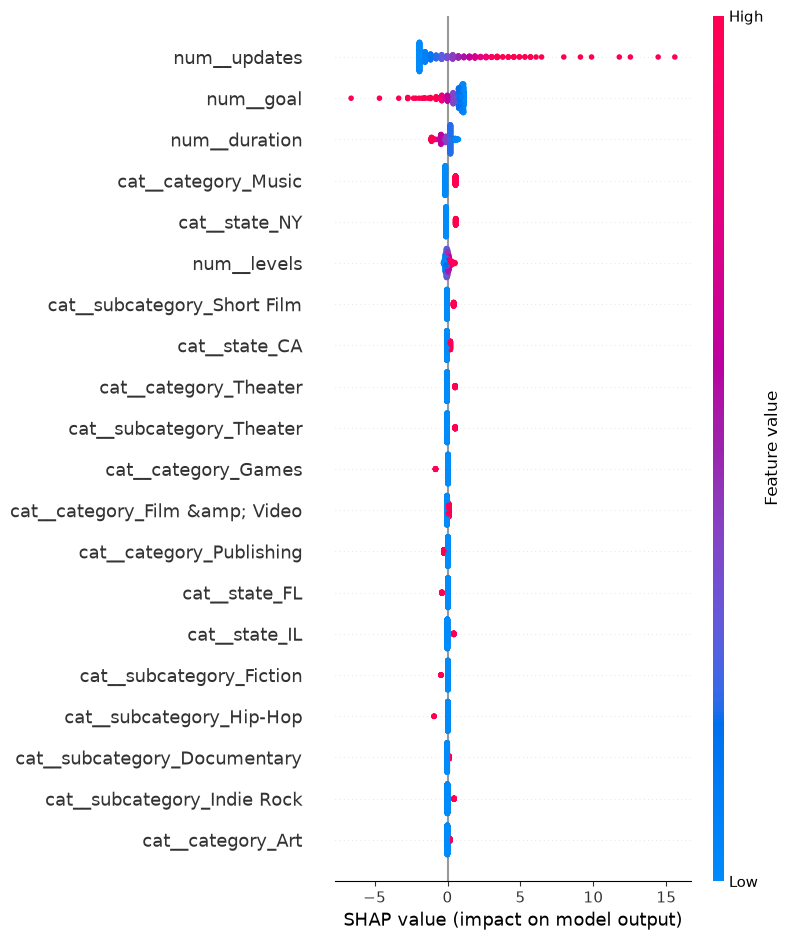

In [5]:
# SHAP summary plot
shap.summary_plot(
    shap_values.values,
    X_test_shap,
    feature_names=feature_names,
    max_display=20
)

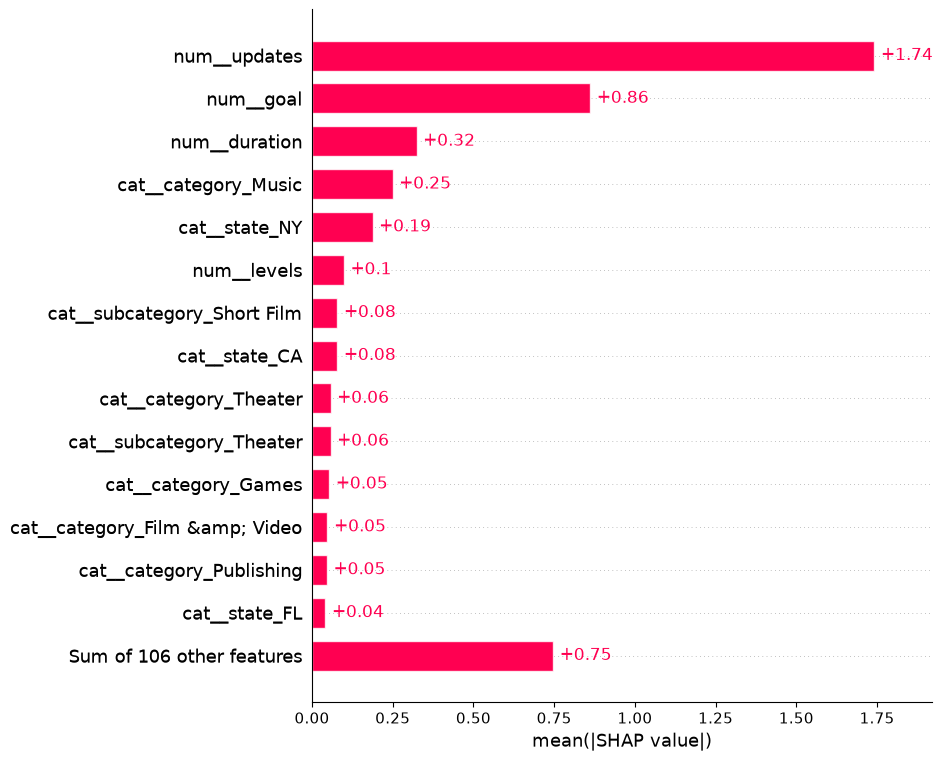

In [8]:
# Add feature names to SHAP explanations
shap_values.feature_names = list(feature_names)

# Plot feature importance with readable names
shap.plots.bar(shap_values, max_display=15)

## 5. Key Findings and Feature Interpretation

SHAP analysis was performed on the Logistic Regression model identified as the best-performing model in Milestone 3 Task 6. We analyzed 500 test campaigns across 120 processed features.

### Most Influential Features

1. **Campaign Updates (1.74):** Updates had the greatest influence on model predictions. Higher numbers of updates were associated with predictions of campaign success, suggesting that the model uses campaign activity as an important predictive signal.

2. **Funding Goal (0.86):** Funding goal was the second most influential feature. Higher funding goals generally pushed predictions toward failure, while lower goals were associated with more favorable predictions.

3. **Campaign Duration (0.32):** Longer campaigns generally pushed predictions toward failure, indicating that duration contributes to the model's assessment of success likelihood.

4. **Campaign Category — Music (0.25):** Campaigns belonging to the Music category received a positive contribution toward predicted success.

5. **Campaign Location — New York (0.19):** The New York state indicator contributed positively to success predictions, suggesting that geographic location influences the model's predictions.

6. **Reward Levels (0.10):** The number of reward levels had a smaller positive association with predicted success.

### Interpretation

The SHAP results indicate that numerical features, particularly campaign updates, funding goal, and duration, have a greater influence on predictions than most individual category, subcategory, and location indicators.

These findings are consistent with patterns observed during Milestone 2 exploratory data analysis, particularly the relationships between funding goals, campaign duration, reward levels, and campaign outcomes.

### Limitations

The model includes `updates`, which may reflect activity occurring after a campaign launches. Consequently, the model's reported 80.25% accuracy may not represent achievable performance for predictions made before launch.

SHAP values explain the model's learned associations rather than establishing causal relationships. Feature importance values represent average absolute contributions to model log-odds, not percentage-point changes in success probability.

## 6. Individual Prediction Explanation

We use a SHAP waterfall plot to examine how individual features
contribute to the Logistic Regression model's prediction for a
specific Kickstarter campaign.

Positive SHAP values push the prediction toward success, while
negative values push it toward failure.

Campaign Details:


,goal,duration,levels,updates,category,subcategory,state
21137,30000.0,59.35,16,7,Film &amp; Video,Documentary,NY


Predicted outcome: Successful
Predicted probability of success: 54.21%


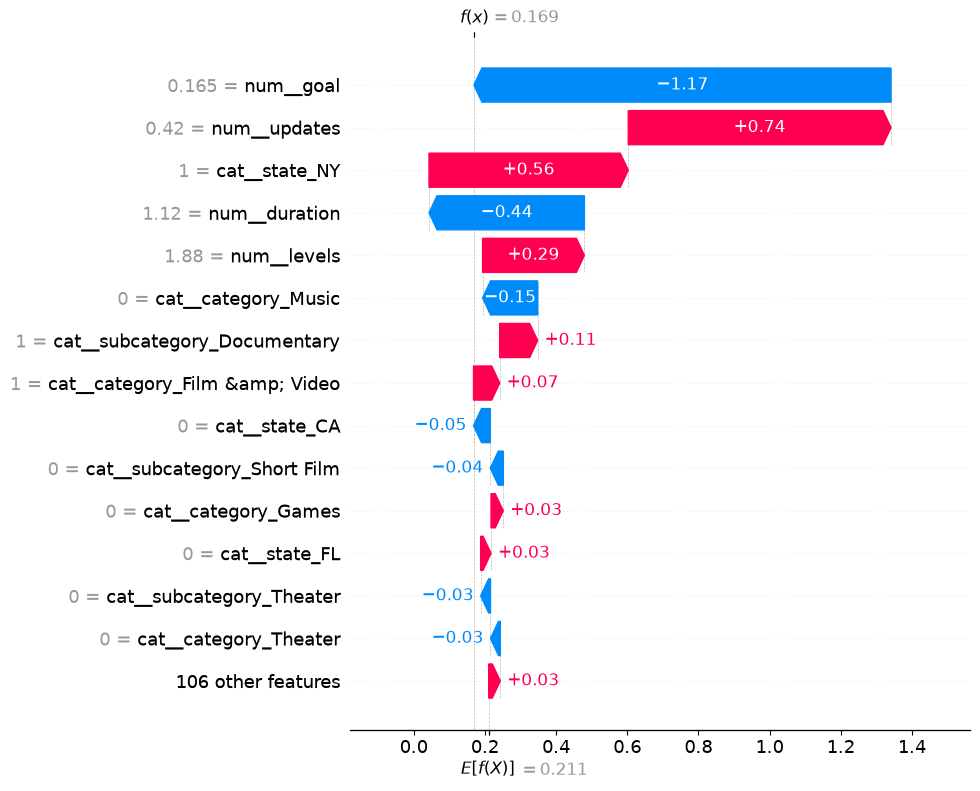

In [9]:
# Select the first campaign from our SHAP test sample
campaign_index = 0

# Display the original campaign features
print("Campaign Details:")
display(X_test.iloc[[campaign_index]])

# Display the model's prediction
prediction = logistic_model.predict(
    X_test_processed[campaign_index:campaign_index + 1]
)[0]

probability = logistic_model.predict_proba(
    X_test_processed[campaign_index:campaign_index + 1]
)[0, 1]

print("Predicted outcome:", "Successful" if prediction == 1 else "Failed")
print(f"Predicted probability of success: {probability:.2%}")

# SHAP waterfall plot
shap.plots.waterfall(
    shap_values[campaign_index],
    max_display=15
)

### Individual Campaign Interpretation

To understand how the Logistic Regression model makes individual predictions, we generated a SHAP waterfall plot for a test campaign.

The selected campaign was a Documentary project in New York with a $30,000 funding goal, approximately 59-day duration, 16 reward levels, and 7 updates.

The model predicted the campaign would succeed with a **54.21% probability**.

The largest negative contribution came from the funding goal (SHAP = −1.17), followed by campaign duration (−0.44). These features pushed the prediction toward failure.

However, campaign updates (+0.74), New York location (+0.56), and reward levels (+0.29) contributed positively, helping offset the negative effects.

Overall, the waterfall plot demonstrates how different campaign characteristics combine to produce an individual prediction. The model's prediction was only slightly above the 50% classification threshold, indicating a relatively uncertain classification.

SHAP contributions are expressed in log-odds and represent model behavior rather than causal effects.